# 01 · Prediction and uncertainty: TabPFN out of the box

Before this lab adds anything to TabPFN, it needs to know what the pretrained model does unaided. This notebook measures that on three small public tables, each chosen to stress a different property:

- **Classification with missing values.** Heart disease in 920 patients pooled from four hospital studies, two thirds of whom lack at least one measurement.
- **Regression with text columns and a predictive distribution.** Sale prices of 1,460 houses in Ames, Iowa, where two of the nine features are raw strings and the question is not only how close the predictions are but whether the model's stated uncertainty can be trusted.
- **Forecasting recast as regression.** Two weeks of hourly German electricity prices, where the model has no notion of time and everything depends on which columns describe each hour.

Every model here is TabPFN with its default settings and no tuning. The numbers printed below come from one run; the [results page](docs/results/01-prediction-and-uncertainty.md) repeats the same tasks over three seeds, adds the references a practitioner would try first (gradient boosting, a regularized linear model, naive forecasts) and puts intervals on the differences.

## How TabPFN predicts

TabPFN is a transformer pretrained on millions of synthetic tables. It never updates its weights on your data. Instead, `fit` stores the training rows as *context*, and `predict` runs one forward pass over the context and the new rows together, so the model infers the relation between features and target from the context in the same pass that it applies it. Two consequences matter for what follows. All the computation happens at prediction time, so repeated predictions on the same context repeat the work unless the context is cached (notebook 02 uses that). And the regressor does not output a number but a distribution: it divides the target's range into many bins and predicts a probability for each, so every point prediction is a summary of that distribution and quantiles come at no extra cost.

## 1. Setup

`helper.py` in this folder holds the data loaders, the model setup and the plots. `init_tabpfn()` selects TabPFN-3.5, the lab's main model, when its license has been accepted, and TabPFN-2 otherwise, and keeps the model on the CPU on a Mac. The datasets are downloaded once into the shared data lake.

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
)

from helper import (
    configure_plots,
    init_tabpfn,
    load_electricity,
    load_heart_disease_full,
    load_housing,
    plot_actual_vs_predicted,
    plot_electricity,
    plot_forecast_comparison,
    plot_quantile_band,
)

configure_plots(plots=True)

from tabpfn import TabPFNClassifier, TabPFNRegressor
init_tabpfn()

TabPFN v3.5 weights, running locally


'v3.5'

## 2. Classification: heart disease with missing measurements

- **Data.** 920 patients from the Cleveland, Hungarian, Swiss and Long Beach studies, split into 700 context patients and 220 test patients, stratified by outcome.
- **Target.** 1 when angiography found narrowing in at least one major vessel, 0 otherwise.
- **Missing values.** About two thirds of the patients lack at least one measurement, coded as `NaN`. TabPFN takes them as they are; nothing is imputed.

In [2]:
X_train, X_test, y_train, y_test = load_heart_disease_full(
    train_size=700, test_size=220,
)

X_train.head(3)

,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,n_major_vessels,thalassemia
111,56.0,1.0,4.0,125.0,249.0,1.0,2.0,144.0,1.0,1.2,2.0,1.0,3.0
490,62.0,1.0,2.0,140.0,271.0,0.0,0.0,152.0,0.0,1.0,1.0,NaN,NaN
461,55.0,0.0,2.0,130.0,394.0,0.0,2.0,150.0,0.0,0.0,NaN,NaN,NaN


In [3]:
y_train.head(3)

111    1
490    0
461    0
Name: heart_disease, dtype: int64

The interface is scikit-learn's, but `fit` trains nothing: it validates and preprocesses the 700 rows and keeps them as context. No hyperparameters are chosen and no categorical columns are declared; TabPFN infers which columns behave like categories.

In [4]:
classifier = TabPFNClassifier()
classifier.fit(X_train, y_train)

,n_estimators,'auto'
,auto_scale_n_estimators,True
,categorical_features_indices,None
,group_col,None
,softmax_temperature,'auto'
,balance_probabilities,False
,average_before_softmax,False
,model_path,'auto'
,device,'auto'
,ignore_pretraining_limits,False
,inference_precision,'auto'


### One patient

`predict` returns the class with the higher probability; `predict_proba` returns the probabilities themselves, which are what a risk decision should rest on. Whether those probabilities are calibrated is a separate question, measured by the log loss on the results page.

In [5]:
patient = X_test.iloc[[0]]
display(patient)

,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,n_major_vessels,thalassemia
416,50.0,1.0,2.0,170.0,209.0,0.0,1.0,116.0,0.0,0.0,NaN,NaN,NaN


In [6]:
prediction = classifier.predict(patient)[0]


print(f"predicted: {prediction:.0f}   "
      f"actual: {y_test.iloc[0]:.0f}")

predicted: 0   actual: 0


In [7]:
proba = classifier.predict_proba(patient)[0]
print(f"P(healthy: label=0) = {proba[0]:.2f}   "
      f"P(disease: label=1) = {proba[1]:.2f}")

P(healthy: label=0) = 0.92   P(disease: label=1) = 0.08


### All 220 test patients

The confusion matrix separates the two kinds of error. Rows are the true status and columns the prediction, so the off-diagonal cells are the false alarms (top right) and the missed diagnoses (bottom left).

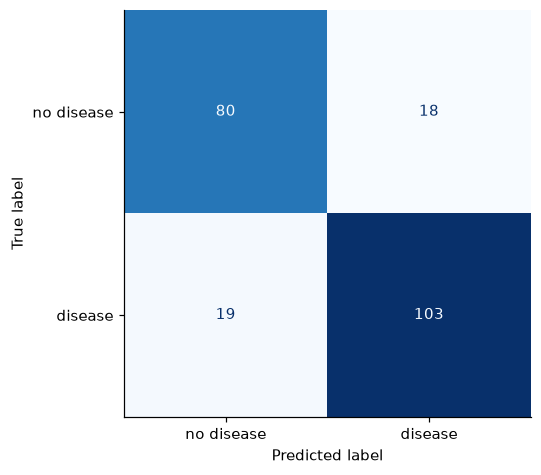

In [8]:
predictions = classifier.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["no disease", "disease"],
    cmap="Blues",
    colorbar=False,
);


Two rates summarize them:

- **Precision**: of the patients flagged as diseased, the fraction who are. Low precision means unnecessary follow-up.
- **Recall**: of the diseased patients, the fraction flagged. Low recall means missed diagnoses, usually the costlier error.

In [9]:
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)

print(f"precision: {precision:.2f}")
print(f"recall:    {recall:.2f}")

precision: 0.85
recall:    0.84


## 3. Regression: house prices and their uncertainty

- **Data.** The Ames housing data ([OpenML 42165](https://www.openml.org/d/42165), De Cock 2011): 1,460 sales from 2006 to 2010, nine of the original eighty features, 1,300 context houses and 160 test houses.
- **Mixed types.** `Neighborhood` and `KitchenQual` are raw strings. They are passed as they are, with no encoding.

The only code change from classification is the estimator.

In [10]:
X_train_h, X_test_h, y_train_h, y_test_h = load_housing(
    train_size=1300,
    test_size=160,
)
X_train_h.head(3)

,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,LotArea,KitchenQual,Neighborhood
223,4,864,2,864,1971,1,10500,TA,NAmes
1233,5,1188,2,1188,1959,1,12160,TA,NAmes
989,7,1576,2,770,2006,2,8125,Gd,Somerst


In [11]:
y_train_h.head(3)

223      97000.0
1233    142000.0
989     197000.0
Name: sale_price, dtype: float64

In [12]:
reg = TabPFNRegressor()
reg.fit(X_train_h, y_train_h)

,n_estimators,'auto'
,auto_scale_n_estimators,True
,categorical_features_indices,None
,group_col,None
,softmax_temperature,'auto'
,average_before_softmax,False
,model_path,'auto'
,device,'auto'
,ignore_pretraining_limits,False
,inference_precision,'auto'
,fit_mode,'fit_preprocessors'


### One house, as a distribution

Because the regressor predicts a distribution over prices, a single house gets several summaries of it:

- `predict(X)` returns the **mean** of the distribution, the expected price.
- `predict(X, output_type="quantiles", quantiles=[0.1, 0.5, 0.9])` returns the 10th, 50th and 90th **percentiles**. The 10th to 90th percentile range is the model's 80% prediction interval, and the 50th is the median.

In [13]:
house_ind = 5
house = X_test_h.iloc[[house_ind]]
display(house)

,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,LotArea,KitchenQual,Neighborhood
1013,5,1022,1,1022,1910,1,7200,TA,OldTown


In [14]:
mean_price = reg.predict(house)[0]
print(f"mean:            ${mean_price:,.0f}")
print(f"actual price:    ${y_test_h.iloc[house_ind]:,.0f}")


q10, q50, q90 = reg.predict(
    house,
    output_type="quantiles",
    quantiles=[0.1, 0.5, 0.9],
)

print(f"10th percentile: ${q10[0]:,.0f}")
print(f"median:          ${q50[0]:,.0f}")
print(f"90th percentile: ${q90[0]:,.0f}")


mean:            $100,295
actual price:    $85,000


10th percentile: $77,871
median:          $102,058
90th percentile: $119,904


Two houses can share a predicted mean and differ in how sure the model is: a narrow interval says the context pins the price down, a wide one says it does not. A point prediction alone hides that difference.

### All 160 test houses

Two scores, both on the dollar scale of the target:

- **MAE**, the mean absolute error, in dollars.
- **$R^2$**, the share of the price variance across houses that the predictions explain: 1 is perfect, 0 is no better than predicting the average price.

In [15]:
point = reg.predict(X_test_h)

comparison = pd.DataFrame(
    {
        "predicted ($1000s)": (point[:6] / 1000).round(0),
        "actual ($1000s)": (y_test_h.values[:6] / 1000),
    }
)
print(comparison)

   predicted ($1000s)  actual ($1000s)
0               309.0          200.624
1               132.0          133.000
2               132.0          110.000
3               212.0          192.000
4               103.0           88.000
5               100.0           85.000


In [16]:
mae = mean_absolute_error(y_test_h, point)
print(f"MAE: ${mae:,.0f}")
print(f"R2:  {r2_score(y_test_h, point):.2f}")

MAE: $15,994
R2:  0.90


Each dot below is a test house, actual price against predicted; the dashed line is a perfect prediction, and a dot's vertical distance from it is that house's error.

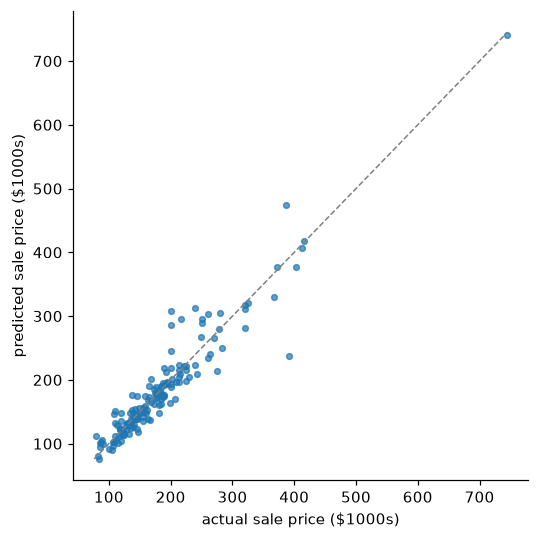

In [17]:
plot_actual_vs_predicted(
    y_test_h / 1000,
    point / 1000,
    unit="sale price ($1000s)",
)

### Is the 80% interval an 80% interval?

An interval is useful only if it is calibrated: across many houses, the true price should fall between the 10th and 90th percentiles about 80% of the time. The coverage below is that fraction on the 160 test houses. With 160 houses, the coverage of a perfectly calibrated interval still varies from sample to sample with a standard deviation of about three percentage points, so anything from roughly 74% to 86% is consistent with calibration. The plot shows every house's interval, sorted by predicted median, with the houses the interval missed in red.

the 10-90 band covers 80% of 160 test houses


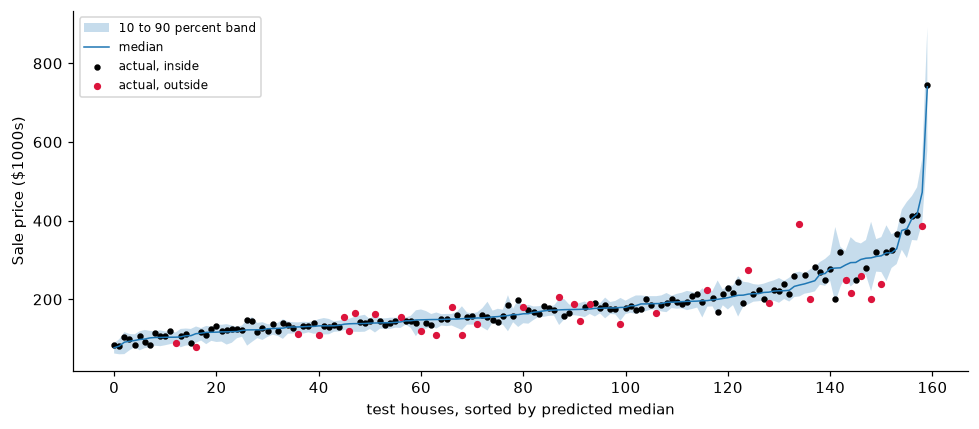

In [18]:
low, median, high = reg.predict(
    X_test_h,
    output_type="quantiles",
    quantiles=[0.1, 0.5, 0.9]
)

actual = y_test_h.values
inside = (actual >= low) & (actual <= high)
print(f"the 10-90 band covers {inside.mean():.0%} "
      f"of {len(actual)} test houses")

plot_quantile_band(
    actual / 1000,
    low / 1000,
    median / 1000,
    high / 1000,
    "Sale price ($1000s)",
    unit="test houses",
)

## 4. Forecasting as regression on the right columns

TabPFN treats rows as an unordered set and has no built-in notion of time. A forecast is still a regression: the future rows are rows whose target is unknown. What the model can use is decided entirely by the columns that describe each hour, so the experiment here holds the model fixed and changes only those columns.

- **Data.** Hourly day-ahead prices for the German and Luxembourg bidding zone, 4 to 19 March 2024: 336 hours of history as context and the final 48 hours to forecast. Prices follow a daily cycle and a weekly rhythm, with occasional spikes.

history:  336 hours
held out: 48 hours


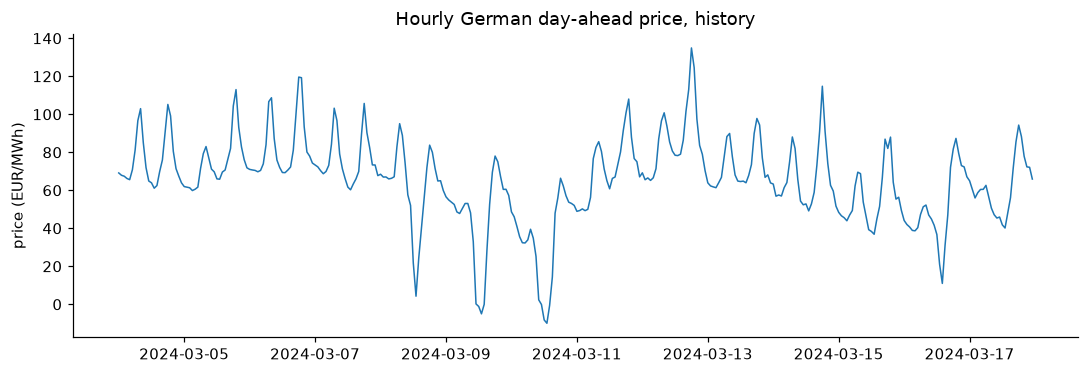

In [19]:
history, future = load_electricity(horizon=48)

print(f"history:  {len(history)} hours")
print(f"held out: {len(future)} hours")

plot_electricity(history)

In [20]:
history.head(3)

,hour,price_eur,load_forecast,renewables_forecast
0,2024-03-04 00:00:00,69.13,43119.65,10416.275
1,2024-03-04 01:00:00,67.90,41812.35,9744.850
2,2024-03-04 02:00:00,67.41,41582.85,9419.575


### The clock alone

The first attempt describes each hour only by its position in time, the number of hours since the start of the history. Every future hour is then a number larger than any in the context, so the model has nothing to anchor it to and can only extrapolate from the edge of what it has seen. (Local TabPFN refuses datetime columns outright, which is why the timestamp is converted to a number here.)

In [21]:
def clock_as_number(df):
    elapsed = (df["hour"] - history["hour"].iloc[0]) / pd.Timedelta(hours=1)
    return elapsed.to_frame("hour")

reg_ts = TabPFNRegressor()

reg_ts.fit(clock_as_number(history), history["price_eur"])
forecast_price = reg_ts.predict(clock_as_number(future))

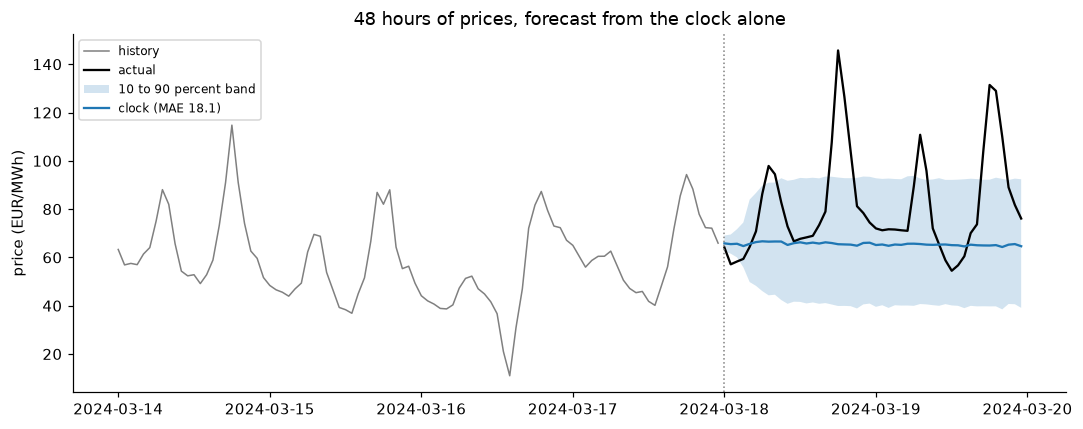

In [22]:
low_price, _, high_price = reg_ts.predict(clock_as_number(future),
                                          output_type="quantiles",
                                          quantiles=[0.1, 0.5, 0.9])

plot_forecast_comparison(
    history, future,
    {"clock": forecast_price}, time_col="hour",
    target_col="price_eur", ylabel="price (EUR/MWh)",
    title="48 hours of prices, forecast from the clock alone",
    band=(low_price, high_price),
)

### Calendar features

The repeating structure becomes visible once each hour is described by where it falls in the cycles:

- `hour_of_day`, 0 to 23, places the hour on the daily cycle;
- `day_of_week`, 0 (Monday) to 6, separates working days from the weekend.

Every future hour now has neighbours in the context: the same hour on earlier days.

In [23]:
def add_calendar_features(df):
    out = df.copy()
    out["hour_of_day"] = out["hour"].dt.hour
    out["day_of_week"] = out["hour"].dt.day_of_week
    return out


FEATURES = ["hour_of_day", "day_of_week"]

history_cal = add_calendar_features(history)
future_cal = add_calendar_features(future)

reg_ts = TabPFNRegressor()
reg_ts.fit(history_cal[FEATURES], history_cal["price_eur"])

forecast_price = reg_ts.predict(future_cal[FEATURES])

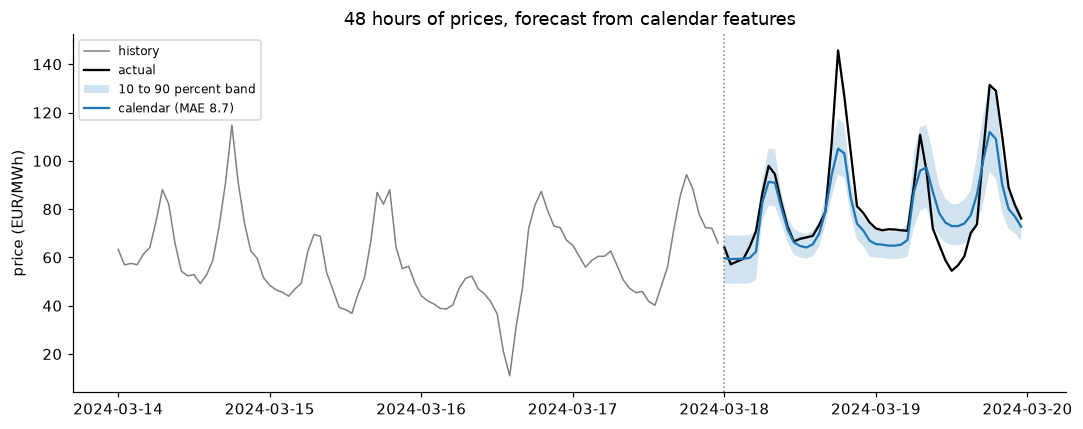

In [24]:
low_price, _, high_price = reg_ts.predict(future_cal[FEATURES],
                                          output_type="quantiles",
                                          quantiles=[0.1, 0.5, 0.9])

plot_forecast_comparison(
    history, future,
    {"calendar": forecast_price}, time_col="hour",
    target_col="price_eur", ylabel="price (EUR/MWh)",
    title="48 hours of prices, forecast from calendar features",
    band=(low_price, high_price),
)

### Market conditions

Prices depend on how much power is demanded and how much wind and solar supply there is. Transmission operators publish day-ahead forecasts of both before the hours they describe, so they are legitimately known for the hours being forecast. Adding them as two more columns, `load_forecast` and `renewables_forecast`, gives the model the market conditions as well as the clock.

calendar MAE:          8.69 EUR/MWh
calendar + market MAE: 7.88 EUR/MWh


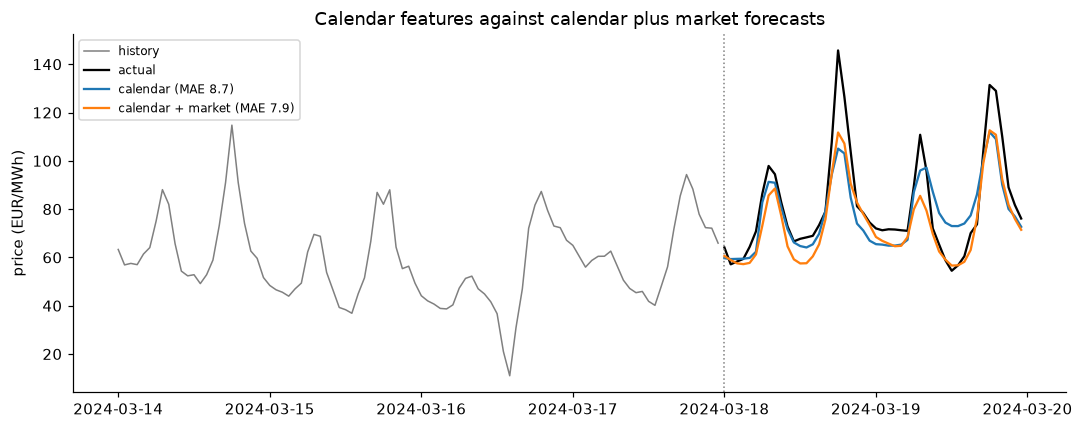

In [25]:
MARKET_FEATURES = FEATURES + ["load_forecast", "renewables_forecast"]

reg_market = TabPFNRegressor()
reg_market.fit(history_cal[MARKET_FEATURES], history_cal["price_eur"])
market_price = reg_market.predict(future_cal[MARKET_FEATURES])

print(f"calendar MAE:          {mean_absolute_error(future['price_eur'], forecast_price):.2f} EUR/MWh")
print(f"calendar + market MAE: {mean_absolute_error(future['price_eur'], market_price):.2f} EUR/MWh")

plot_forecast_comparison(
    history, future,
    {"calendar": forecast_price, "calendar + market": market_price},
    time_col="hour", target_col="price_eur", ylabel="price (EUR/MWh)",
    title="Calendar features against calendar plus market forecasts",
)

The model never changed between the three forecasts; only the columns did. For an in-context learner, choosing the features is choosing what the model is allowed to read before it predicts, which makes the description of each row the main lever a method has. That is the lever this lab's routes pull on: in the perturbation-response work, the row is a gene in a two-gene perturbation, and the question is which descriptors of it let the model predict how the two effects combine.

## What this notebook establishes

- **One interface, three task types.** Classification with missing values, regression with text columns and forecasting run through the same two estimators with default settings and no preprocessing.
- **A distribution, not a number, calibrated only where the test rows resemble the context.** Every regression prediction comes with quantiles. On the housing test set the 80% interval covers 80% of the houses; on the electricity horizon, 48 future hours that include price spikes, the bands drawn above cover far fewer of the actual prices than 80%, which the results page quantifies.
- **The columns decide.** The same model forecasts a flat line from the clock and follows the daily cycle from calendar features; market forecasts help further.

Whether these numbers are good is a comparative question. The [results page](docs/results/01-prediction-and-uncertainty.md) answers it against untuned gradient boosting, regularized linear models and naive forecasts, over three seeds and both TabPFN versions.